# Approaching Quality Control on MERFISH

In [1]:
%load_ext watermark
%watermark -v -p matplotlib,numpy,pandas,scanpy,seaborn,squidpy

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

matplotlib: 3.11.2
numpy     : 2.4.6
pandas    : 3.1.0
scanpy    : 1.12.4
seaborn   : 0.13.2
squidpy   : 1.8.3



This tutorial uses data from ... . It focuses primarily on background noise, but the same approach can be extended to other parameters, such as `total_counts`, `n_genes_by_counts`, and others.

**Note:** This approach can also be applied to other spatial technologies, although the relevant parameters may differ.

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import seaborn as sns

import matplotlib.pyplot as plt

c:\Users\user\OneDrive\Desktop\GitHub\mini-spatial-series\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
adata = sc.read_h5ad("D:/BioWorkbench/merfish.h5ad")
adata.var_names_make_unique()
adata.var["genes"] = ~adata.var_names.str.startswith("Blank-")
adata.var["blanks"] = adata.var_names.str.startswith("Blank-")
adata

AnnData object with n_obs × n_vars = 45139 × 550
    obs: 'center_x', 'center_y', 'center_z', 'volume', 'area', 'polygon_center_x', 'polygon_center_y', 'polygon_center_z', 'SpotTable_cell_id'
    var: 'probe_name', 'cells_with_reads', 'segmented_total_reads', 'unsegmented_total_reads', 'genes', 'blanks'
    uns: 'SIS_repo_hash', 'cell_polygons', 'segmentation_metadata'
    layers: None (.X)

In [4]:
sc.pp.calculate_qc_metrics(
    adata,
    percent_top=None,
    inplace=True,
    # parallel=None
)

In [5]:
adata.obsm["spatial"] = adata.obs[["center_x", "center_y"]].to_numpy(dtype=float)
adata.obsm["spatial3d"] = adata.obs[["center_x", "center_y", "center_z"]].to_numpy(dtype=float)
adata

AnnData object with n_obs × n_vars = 45139 × 550
    obs: 'center_x', 'center_y', 'center_z', 'volume', 'area', 'polygon_center_x', 'polygon_center_y', 'polygon_center_z', 'SpotTable_cell_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts'
    var: 'probe_name', 'cells_with_reads', 'segmented_total_reads', 'unsegmented_total_reads', 'genes', 'blanks', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'SIS_repo_hash', 'cell_polygons', 'segmentation_metadata'
    obsm: 'spatial', 'spatial3d'
    layers: None (.X)

In [6]:
blank_mask = adata.var_names.str.startswith("Blank-")
blank_counts = np.asarray(adata[:, blank_mask].X.sum(axis=1)).ravel()

total = adata.obs["total_counts"].to_numpy(dtype=float)
adata.obs["blank_counts"] = blank_counts

adata.obs["pct_blank_counts"] = np.divide(
    blank_counts * 100.0,
    total,
    out=np.zeros_like(total),
    where=total > 0,
)

adata.obs["log1p_blank_counts"] = np.log1p(
    adata.obs["blank_counts"]
)

adata.obs["log1p_volume"] = np.log1p(
    adata.obs["volume"]
)

In [7]:
def generate_qc_hist(adata: sc.AnnData, parameters: list):

    fig, axes = plt.subplots(1, len(parameters), figsize=(16, 5))

    for ax, col in zip(axes, parameters):
        # Extract non-missing values
        values = adata.obs[col].dropna()

        # Plot histogram
        sns.histplot(
            values,
            bins=30,
            kde=False,
            ax=ax
        )

        # Calculate and plot median
        median_value = values.median()
        ax.axvline(
            median_value,
            color='red',
            linestyle='--',
            linewidth=2,
            label=f'Median = {median_value:.2f}'
        )

        # Labels and title
        ax.set_title(col)
        ax.set_xlabel(col)
        ax.set_ylabel('Frequency')
        ax.legend()

    plt.tight_layout()
    plt.show()

In [8]:
def generate_qc_violin(adata: sc.AnnData, parameters: list):

    fig, axes = plt.subplots(1, len(parameters), figsize=(16, 5))

    for ax, col in zip(axes, parameters):
        values = adata.obs[col].dropna()
        median_value = values.median()

        # Violin plot
        sns.violinplot(
            y=values,
            ax=ax,
            inner='quartile',
            color='skyblue',
            cut=0
        )

        # Median line
        ax.axhline(
            median_value,
            color='red',
            linestyle='--',
            linewidth=2,
            label=f'Median = {median_value:.2f}'
        )

        ax.set_title(col)
        ax.set_xlabel('')
        ax.set_ylabel(col)
        ax.legend(loc='best')

    plt.tight_layout()
    plt.show()

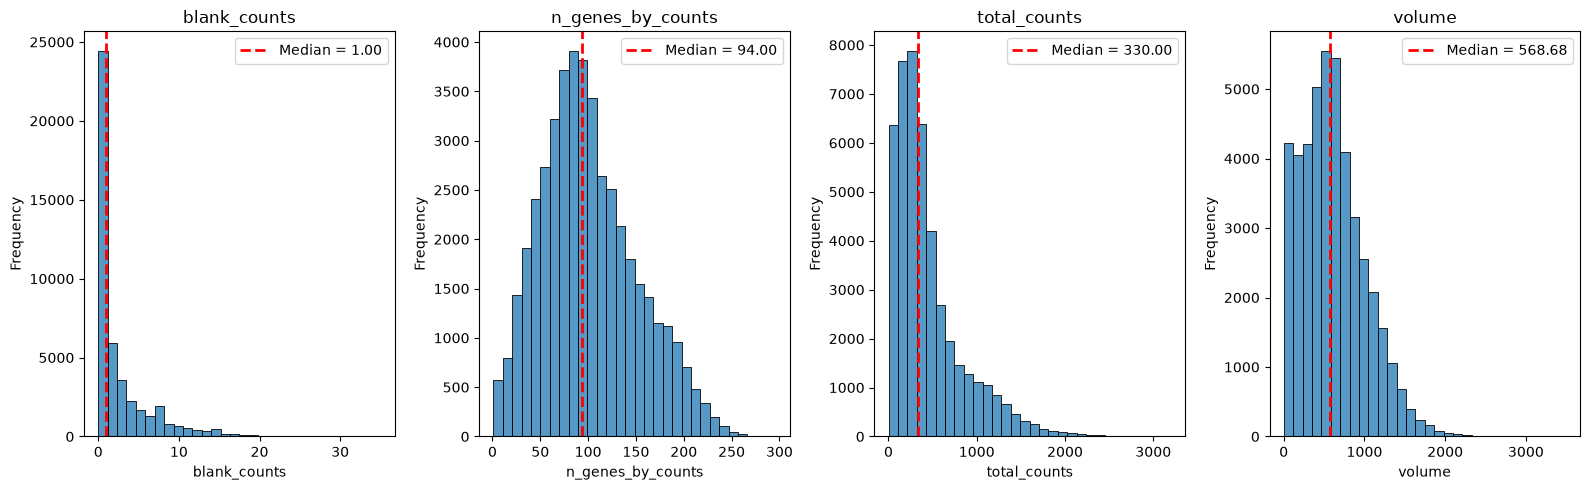

In [9]:
generate_qc_hist(adata=adata, parameters=[
    'blank_counts',
    'n_genes_by_counts',
    'total_counts',
    'volume'
])

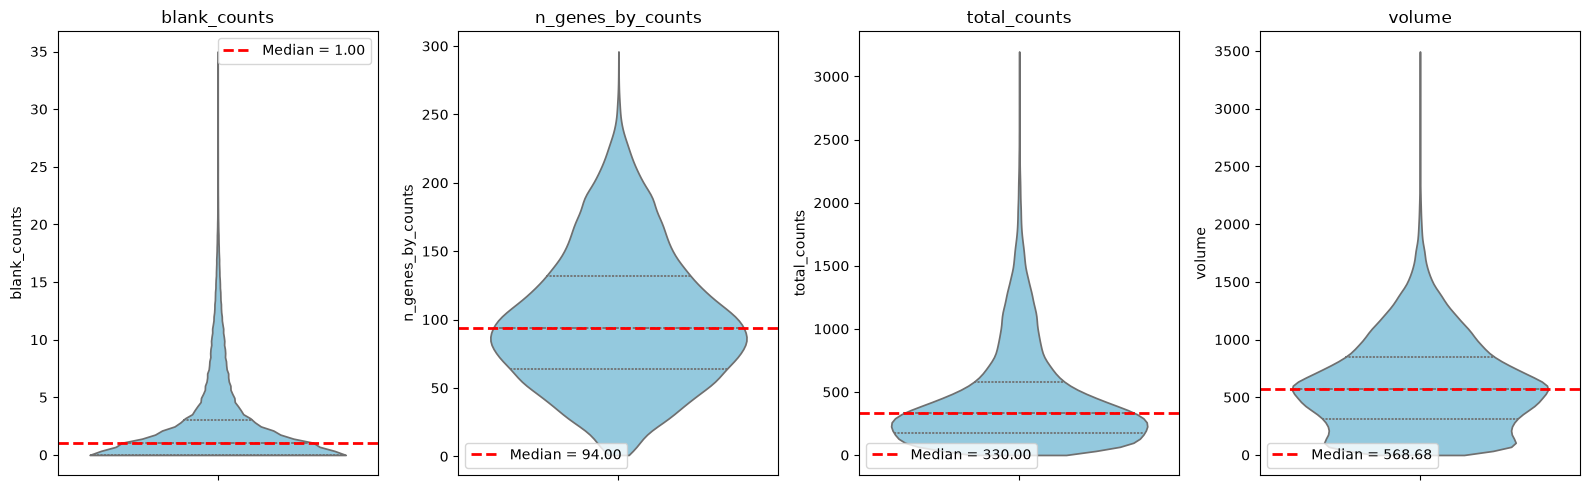

In [10]:
generate_qc_violin(adata=adata, parameters=[
    'blank_counts',
    'n_genes_by_counts',
    'total_counts',
    'volume'
])

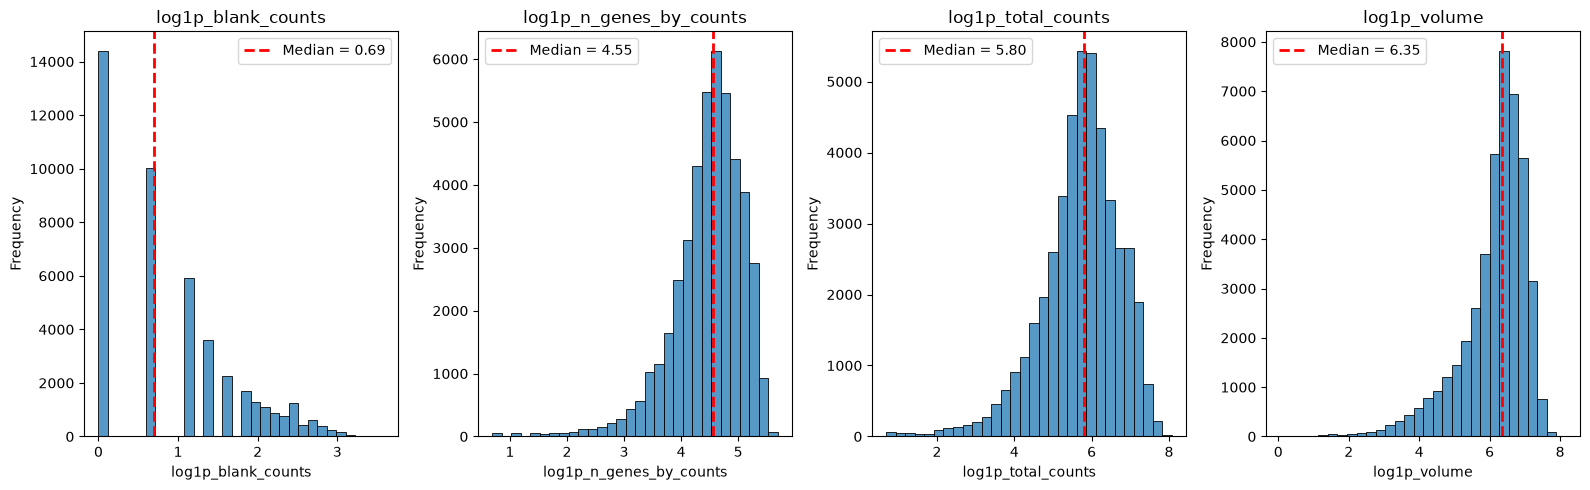

In [11]:
generate_qc_hist(adata=adata, parameters=[
    'log1p_blank_counts',
    'log1p_n_genes_by_counts',
    'log1p_total_counts',
    'log1p_volume'
])

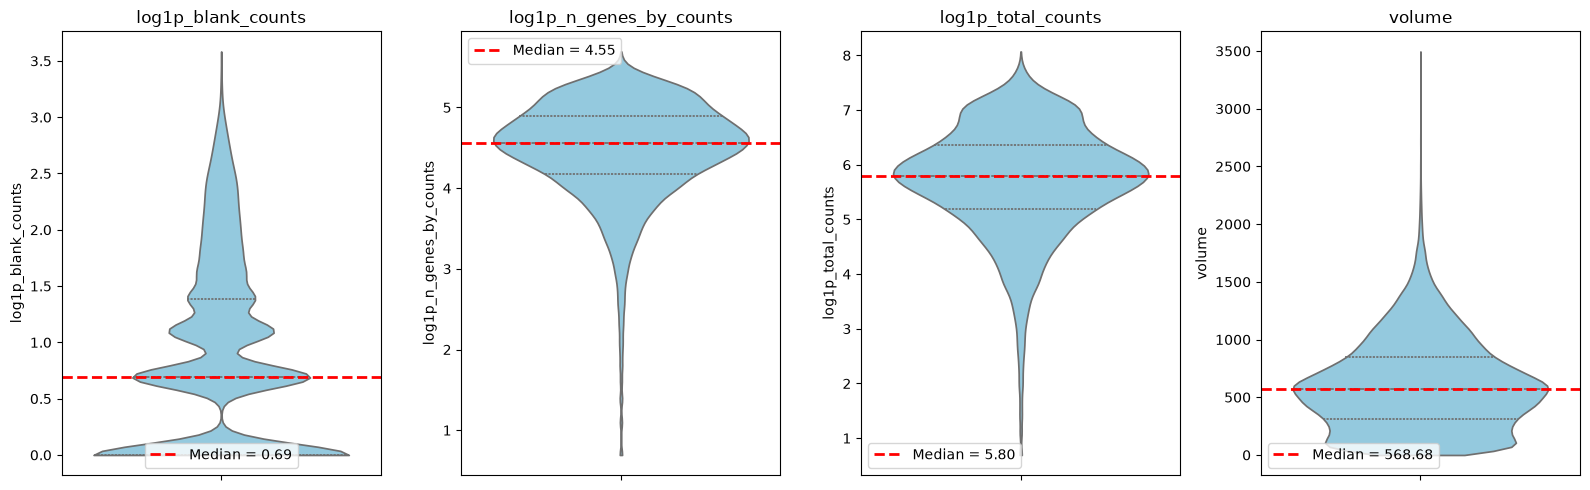

In [12]:
generate_qc_violin(adata=adata, parameters=[
    'log1p_blank_counts',
    'log1p_n_genes_by_counts',
    'log1p_total_counts',
    'volume'
])

In [13]:
adata.obs['blank_counts'].describe()

count    45139.000000
mean         2.695363
std          3.745882
min          0.000000
25%          0.000000
50%          1.000000
75%          3.000000
max         35.000000
Name: blank_counts, dtype: float64

In [14]:
adata.obs['log1p_blank_counts'].describe()

count    45139.000000
mean         0.929898
std          0.831806
min          0.000000
25%          0.000000
50%          0.693147
75%          1.386294
max          3.583519
Name: log1p_blank_counts, dtype: float64

In [15]:
quantile = adata.obs['blank_counts'].quantile(0.75)

condition = adata.obs['blank_counts'] >= quantile

print(f"75th percentile Blank Count: {quantile} \n")

print("Counts:")
print(condition.value_counts())

print("\nPercentages:")
print((condition.value_counts(normalize=True) * 100).round(2))

75th percentile Blank Count: 3.0 

Counts:
blank_counts
False    30383
True     14756
Name: count, dtype: int64

Percentages:
blank_counts
False    67.31
True     32.69
Name: proportion, dtype: float64


## Define cells with high background noise

In [21]:
quantile = adata.obs['blank_counts'].quantile(0.95)

condition = adata.obs['blank_counts'] > quantile

print(f"95th percentile Blank Count: {quantile} \n")

print("Counts:")
print(condition.value_counts())

print("\nPercentages:")
print((condition.value_counts(normalize=True) * 100).round(2))

95th percentile Blank Count: 11.0 

Counts:
blank_counts
False    43221
True      1918
Name: count, dtype: int64

Percentages:
blank_counts
False    95.75
True      4.25
Name: proportion, dtype: float64


In [22]:
adata.obs['blank_threshold'] = adata.obs['blank_counts'] > quantile

adata.obs["blank_threshold"] = (
    adata.obs["blank_threshold"]
    .astype(str)
    .replace({
        "True": "Above",
        "False": "Below",
        "1": "Above",
        "0": "Below",
        # "nan": "NA",
    })
)

adata.obs["blank_threshold"] = pd.Categorical(
    adata.obs["blank_threshold"],
    categories=["Below", "Above"],
)


c:\Users\user\OneDrive\Desktop\GitHub\mini-spatial-series\env\Lib\site-packages\squidpy\pl\_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
c:\Users\user\OneDrive\Desktop\GitHub\mini-spatial-series\env\Lib\site-packages\squidpy\pl\_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
c:\Users\user\OneDrive\Desktop\GitHub\mini-spatial-series\env\Lib\site-packages\squidpy\pl\_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


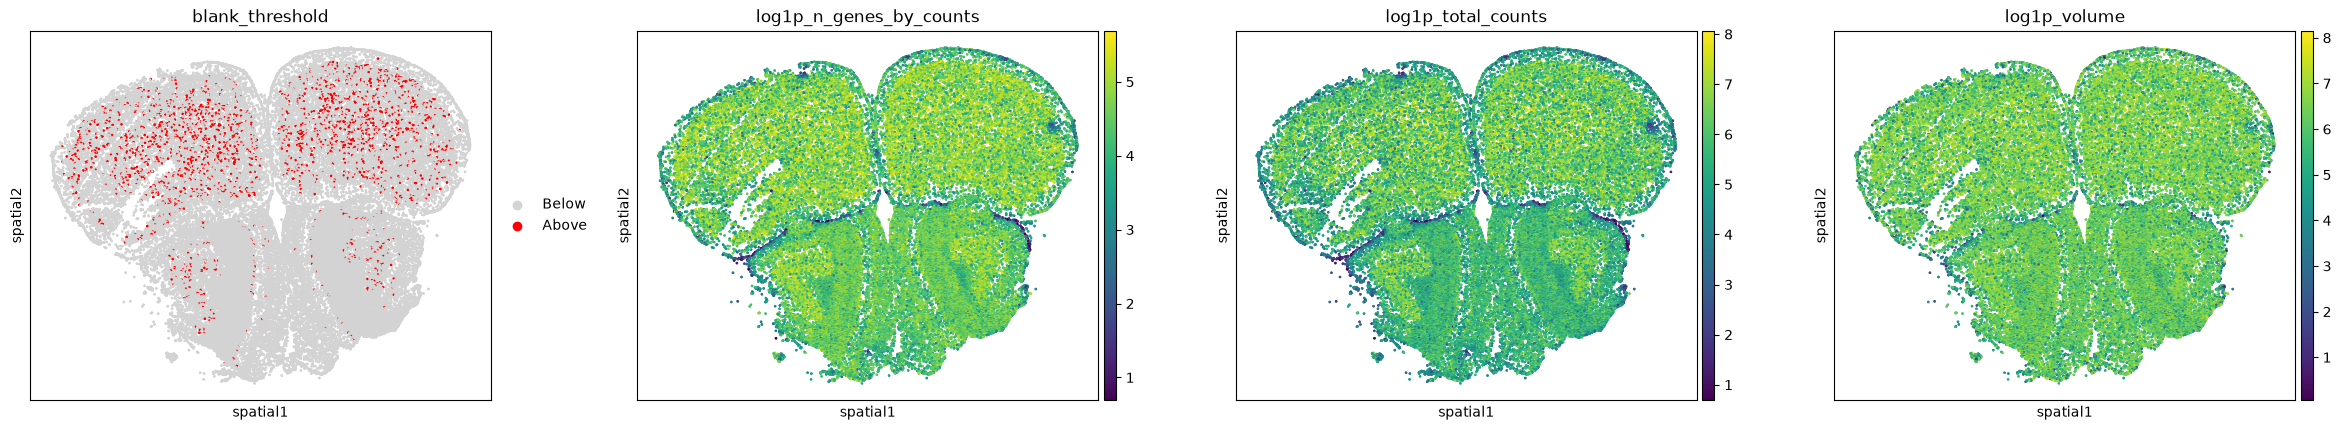

In [28]:
adata.uns.pop("blank_threshold_colors", None)
adata.uns["blank_threshold_colors"] = [
    "lightgray",  # Below
    "red",        # Above
    # "lightgray",  # NA
]

sq.pl.spatial_scatter(
    adata,
    shape=None,
    color=[
        "blank_threshold",
        "log1p_n_genes_by_counts",
        "log1p_total_counts",
        "log1p_volume",
    ],
    # wspace=0.2,
)

In [25]:
sdata = adata[adata.obs['blank_threshold'] == "Above"].copy()
sdata

AnnData object with n_obs × n_vars = 1918 × 550
    obs: 'center_x', 'center_y', 'center_z', 'volume', 'area', 'polygon_center_x', 'polygon_center_y', 'polygon_center_z', 'SpotTable_cell_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'blank_counts', 'pct_blank_counts', 'log1p_blank_counts', 'log1p_volume', 'blank_threshold'
    var: 'probe_name', 'cells_with_reads', 'segmented_total_reads', 'unsegmented_total_reads', 'genes', 'blanks', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'SIS_repo_hash', 'cell_polygons', 'segmentation_metadata', 'blank_threshold_colors'
    obsm: 'spatial', 'spatial3d'
    layers: None (.X)

## Conclusion

1. Spike-in genes (Blanks) were modelled at the cell level
2. The threshold was set at the 95th percentile, giving 1918 cells with a high amount of noise
3. The blank threshold, like all parameter should be set per experiment